# PCA in DupeLens: done by hand, step by step

DupeLens decides whether two online listings are the **same product**. For every pair of listings it measures
**12 features** (how similar the photos are, how similar the titles are, whether the model numbers match, ...),
and a logistic-regression model turns them into a decision.

This notebook does PCA on those 12 features **manually** (mean, centring, covariance matrix, eigenvalues,
eigenvectors, projection), checks the result with `sklearn`, and finds **which features matter most**.
Then it shows the two other places PCA works inside DupeLens:
- compressing the CLIP photo vectors (512 numbers) and the MPNet title vectors (768 numbers) to 32,
- the **Genuine Look** check: a photo that PCA cannot rebuild from the other listings is not the real product.

Data: 430 pairs of real listings from live Indian searches, labelled *same*, *variant* (same product, another
colour/size/pack) or *different* (labelled by Claude, an AI assistant, not humans).

## 1. Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/pair_features.csv")
features = ["img_cos", "txt_cos", "tfidf_cos", "phash_dist", "num_match", "num_conflict",
            "mutual", "rank_min", "rank_max", "len_ratio", "dino_cos", "colour_dist"]
A = df[features]
Y = df["label"]
print(A.shape)
print(Y.value_counts())
A.head()

(430, 12)
label
different    217
variant      138
same          75
Name: count, dtype: int64


,img_cos,txt_cos,tfidf_cos,phash_dist,num_match,num_conflict,mutual,rank_min,rank_max,len_ratio,dino_cos,colour_dist
0,0.92205,0.97464,0.78267,22.0,0.0,0.0,1.0,3.0,4.0,0.96154,0.81828,0.99933
1,0.34947,0.89267,0.43362,22.0,0.0,0.0,1.0,9.0,17.0,0.71875,-0.00949,0.01302
2,0.72990,0.81446,0.46649,28.0,0.0,0.0,1.0,8.0,13.0,0.26471,0.86878,0.05120
3,0.31087,0.93055,0.50032,30.0,0.0,0.0,1.0,8.0,17.0,0.48077,0.36833,0.86312
4,0.99760,0.93536,0.75310,0.0,0.0,0.0,1.0,1.0,1.0,0.35461,0.99826,0.11557


| Feature | What it measures for a pair of listings |
| --- | --- |
| img_cos | photo similarity (CLIP neural network, after PCA to 32) |
| txt_cos | title meaning similarity (MPNet neural network, after PCA to 32) |
| tfidf_cos | title word overlap (TF-IDF) |
| phash_dist | perceptual-hash distance of the photos (0 = identical photo) |
| num_match | model numbers / codes the two titles share |
| num_conflict | model numbers that disagree (16 vs 16e, 128 GB vs 256 GB) |
| mutual | 1 if each listing is in the other's 50 nearest neighbours |
| rank_min, rank_max | neighbour rank of one listing in the other's list (1 = most similar) |
| len_ratio | shorter title length / longer title length |
| dino_cos | photo similarity (DINOv2 neural network: the exact object) |
| colour_dist | difference between the colour histograms of the photos |

**A feature that never changes carries no information.** Let us check each feature's spread.

In [2]:
print(A.std().round(4))
constant = [f for f in features if A[f].std() == 0]
print("constant features:", constant)

img_cos          0.1903
txt_cos          0.1848
tfidf_cos        0.1709
phash_dist       8.7027
num_match        0.4419
num_conflict     0.2108
mutual           0.0000
rank_min         8.8110
rank_max        11.8191
len_ratio        0.2174
dino_cos         0.2190
colour_dist      0.2753
dtype: float64
constant features: ['mutual']


`mutual` is 1 for every pair: in a live search of about 40 listings, every listing is always among another's 50
nearest neighbours. A feature with zero variance cannot help PCA (and dividing by its standard deviation of 0 is
impossible), so we drop it. **11 features remain.**

In [3]:
features = [f for f in features if f not in constant]
A = df[features]
print(A.shape)

(430, 11)


## 2. Why we standardise first

PCA looks for the directions of **largest variance**. Our features have very different scales: a cosine
similarity is between 0 and 1, but `rank_max` goes up to 51 and `phash_dist` up to 64. Without scaling, PCA
would simply pick the features with the biggest numbers (just like *Insulin* dominated PC1 in the diabetes
example, because its values are in the hundreds).

In [4]:
print(A.std().round(3).sort_values(ascending=False))

rank_max        11.819
rank_min         8.811
phash_dist       8.703
num_match        0.442
colour_dist      0.275
dino_cos         0.219
len_ratio        0.217
num_conflict     0.211
img_cos          0.190
txt_cos          0.185
tfidf_cos        0.171
dtype: float64


In [5]:
from sklearn.decomposition import PCA

raw = PCA(2).fit(A)                      # PCA WITHOUT scaling (only to show the problem)
print(pd.Series(raw.components_[0], index=features).abs().sort_values(ascending=False).round(3))

rank_max        0.794
rank_min        0.545
phash_dist      0.268
img_cos         0.008
txt_cos         0.007
dino_cos        0.006
colour_dist     0.006
len_ratio       0.006
tfidf_cos       0.005
num_match       0.004
num_conflict    0.000
dtype: float64


PC1 of the unscaled data is almost only `rank_max`, `rank_min` and `phash_dist`, the three features with the
biggest numbers: the biggest numbers win, not the most informative features. So every feature is **standardised** (z-score): subtract its mean and divide by its standard
deviation. Then every feature has mean 0 and standard deviation 1, and PCA compares them fairly.

In [6]:
S = (A - A.mean()) / A.std()
print(S.mean().round(3).values)
print(S.std().round(3).values)

[ 0. -0.  0.  0.  0.  0. -0. -0.  0. -0.  0.]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 3. PCA by hand

**Step 1: mean of every feature, and centre the data**

In [7]:
M = np.mean(S.values.T, axis=1)
C = S.values - M
print(M.round(6))
print(C.shape)

[ 0. -0.  0.  0.  0.  0. -0. -0.  0. -0.  0.]
(430, 11)


**Step 2: covariance matrix (11 x 11)**

In [8]:
V = np.cov(C.T)
print(V.shape)
print(pd.DataFrame(V, index=features, columns=features).round(2))

(11, 11)
              img_cos  txt_cos  tfidf_cos  phash_dist  num_match  \
img_cos          1.00     0.19       0.10       -0.42       0.11   
txt_cos          0.19     1.00       0.47       -0.12       0.04   
tfidf_cos        0.10     0.47       1.00       -0.09      -0.08   
phash_dist      -0.42    -0.12      -0.09        1.00      -0.14   
num_match        0.11     0.04      -0.08       -0.14       1.00   
num_conflict    -0.09     0.07      -0.05        0.08      -0.06   
rank_min        -0.50    -0.49      -0.36        0.30      -0.13   
rank_max        -0.50    -0.51      -0.44        0.26      -0.08   
len_ratio        0.17     0.35       0.37       -0.05       0.05   
dino_cos         0.79     0.16       0.11       -0.48       0.06   
colour_dist     -0.30    -0.03      -0.16        0.19      -0.09   

              num_conflict  rank_min  rank_max  len_ratio  dino_cos  \
img_cos              -0.09     -0.50     -0.50       0.17      0.79   
txt_cos               0.07     -

**Step 3: eigenvalues and eigenvectors of the covariance matrix, sorted from largest to smallest**

In [9]:
eigvalues, eigenvector = np.linalg.eig(V)
idx = eigvalues.argsort()[::-1]
eigvalues = eigvalues[idx]
eigenvector = eigenvector[:, idx]
print(eigvalues.round(4))

[3.6214 1.7353 1.0355 1.0101 0.824  0.7068 0.6675 0.5518 0.4455 0.2402
 0.1619]


Each eigenvector is a **principal component** (a direction made of all 12 features); its eigenvalue is the
variance of the data along that direction. The sum of the eigenvalues equals the total variance, which is 11 here
(11 standardised features, each with variance 1).

In [10]:
print("sum of eigenvalues:", eigvalues.sum().round(4))
ratio = eigvalues / eigvalues.sum()
cumulative = np.cumsum(ratio)
print(pd.DataFrame({"eigenvalue": eigvalues.round(3), "explained %": (100 * ratio).round(1),
                    "cumulative %": (100 * cumulative).round(1)}, index=[f"PC{i+1}" for i in range(len(features))]))

sum of eigenvalues: 11.0
      eigenvalue  explained %  cumulative %
PC1        3.621         32.9          32.9
PC2        1.735         15.8          48.7
PC3        1.035          9.4          58.1
PC4        1.010          9.2          67.3
PC5        0.824          7.5          74.8
PC6        0.707          6.4          81.2
PC7        0.667          6.1          87.3
PC8        0.552          5.0          92.3
PC9        0.446          4.1          96.3
PC10       0.240          2.2          98.5
PC11       0.162          1.5         100.0


**Step 4: choose how many components to keep (90% of the variance, like `PCA(0.90)`)**

components needed for 90% of the variance: 8


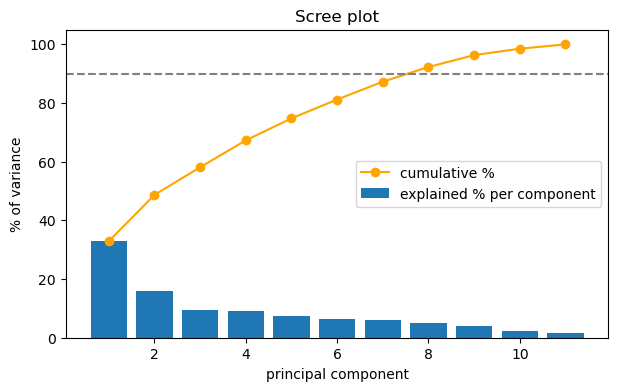

In [11]:
k = int(np.argmax(cumulative >= 0.90)) + 1
print("components needed for 90% of the variance:", k)

plt.figure(figsize=(7, 4))
n = len(features)
plt.bar(range(1, n + 1), 100 * ratio, label="explained % per component")
plt.plot(range(1, n + 1), 100 * cumulative, "o-", color="orange", label="cumulative %")
plt.axhline(90, color="grey", linestyle="--")
plt.xlabel("principal component"); plt.ylabel("% of variance"); plt.legend(); plt.title("Scree plot")
plt.show()

**Step 5: project the data onto the kept components (11 features -> k numbers per pair)**

In [12]:
W = eigenvector[:, :k]
Z = np.dot(C, W)
print(C.shape, "->", Z.shape)
print(Z[:5].round(3))

(430, 11) -> (430, 8)
[[-2.062 -1.412 -0.654 -0.479  2.066 -0.523  0.454 -0.101]
 [ 1.334 -1.521  1.269  0.521 -1.329  1.37  -0.583 -2.334]
 [-0.216  1.323  0.318 -0.814 -1.17   1.559  0.936  0.219]
 [ 1.816 -1.756  0.152  0.203  0.934  1.668  0.753 -0.839]
 [-3.31   1.76  -0.081 -1.129  0.383  2.323 -0.849 -0.447]]


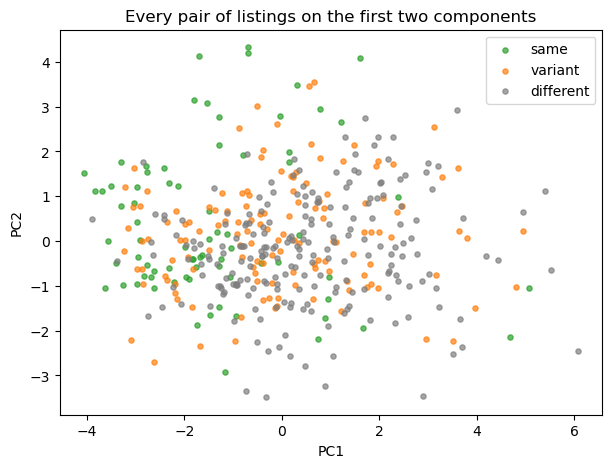

In [13]:
colours = {"same": "tab:green", "variant": "tab:orange", "different": "tab:grey"}
plt.figure(figsize=(7, 5))
for lab, col in colours.items():
    part = Z[(Y == lab).values]
    plt.scatter(part[:, 0], part[:, 1], s=14, color=col, label=lab, alpha=0.7)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(); plt.title("Every pair of listings on the first two components")
plt.show()

**What PC1 means:** its loadings (section 5) are positive for the distance-like features (`rank_min`, `rank_max`,
`phash_dist`) and negative for all the similarities (`img_cos`, `dino_cos`, `txt_cos`, `tfidf_cos`). So PC1 is a
**"how different do these two listings look and read"** axis. The average PC1 of each group:

In [14]:
print(pd.Series(Z[:, 0], index=df.index).groupby(Y).mean().round(2))

label
different    0.51
same        -1.38
variant     -0.05
dtype: float64


*Same* pairs sit furthest left, *different* pairs furthest right, *variants* in between, but the groups overlap a
lot: every pair comes from the same search (two iPhone 16 listings, or an iPhone 16 and an iPhone 16 Pro), so
these are hard cases, and one direction alone cannot separate them.

## 4. Check with sklearn

In [15]:
pca = PCA(0.90)
pca.fit(S)
print("components kept:", pca.n_components_)
print("explained variance (sklearn):", pca.explained_variance_.round(4))
print("explained variance (by hand):", eigvalues[:pca.n_components_].round(4))
print("ratio:", pca.explained_variance_ratio_.round(4))

components kept: 8
explained variance (sklearn): [3.6214 1.7353 1.0355 1.0101 0.824  0.7068 0.6675 0.5518]
explained variance (by hand): [3.6214 1.7353 1.0355 1.0101 0.824  0.7068 0.6675 0.5518]
ratio: [0.3292 0.1578 0.0941 0.0918 0.0749 0.0643 0.0607 0.0502]


In [16]:
B = pca.transform(S)
# an eigenvector may come out with the opposite sign (v and -v are the same direction),
# so we compare absolute values
print("same components:", np.allclose(np.abs(pca.components_.T), np.abs(W)))
print("same projected data:", np.allclose(np.abs(B), np.abs(Z)))

same components: True


same projected data: True


## 5. Which features matter most (loadings)

The **loadings** of a component are the entries of its eigenvector: how much each original feature contributes.
A large absolute loading = an important feature for that component.

In [17]:
loadings_pc1 = pca.components_[0]
contributions = pd.Series(loadings_pc1, index=features)
print(contributions.abs().sort_values(ascending=False).round(3))

rank_max        0.437
rank_min        0.424
img_cos         0.389
dino_cos        0.345
txt_cos         0.309
tfidf_cos       0.271
phash_dist      0.266
len_ratio       0.246
colour_dist     0.227
num_match       0.080
num_conflict    0.026
dtype: float64


In [18]:
loadings_pc2 = pca.components_[1]
contributions = pd.Series(loadings_pc2, index=features)
print(contributions.abs().sort_values(ascending=False).round(3))

dino_cos        0.409
tfidf_cos       0.389
txt_cos         0.383
len_ratio       0.366
img_cos         0.344
phash_dist      0.337
colour_dist     0.233
num_conflict    0.219
rank_max        0.170
num_match       0.159
rank_min        0.113
dtype: float64


In [19]:
loadings_pc3 = pca.components_[2]
contributions = pd.Series(loadings_pc3, index=features)
print(contributions.abs().sort_values(ascending=False).round(3))

num_conflict    0.833
colour_dist     0.349
tfidf_cos       0.301
dino_cos        0.191
img_cos         0.171
phash_dist      0.132
num_match       0.096
txt_cos         0.024
rank_min        0.023
len_ratio       0.022
rank_max        0.001
dtype: float64


In [20]:
loadings = pd.DataFrame(pca.components_.T, index=features,
                        columns=[f"PC{i+1}" for i in range(pca.n_components_)])
loadings.round(2)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
img_cos,-0.39,0.34,0.17,-0.11,0.07,0.24,0.29,0.18
txt_cos,-0.31,-0.38,0.02,0.06,0.22,-0.32,0.06,0.39
tfidf_cos,-0.27,-0.39,-0.30,-0.20,0.03,-0.12,-0.40,0.35
phash_dist,0.27,-0.34,-0.13,-0.02,-0.36,0.27,0.63,0.41
num_match,-0.08,0.16,-0.10,0.93,-0.02,0.01,-0.07,0.25
num_conflict,0.03,-0.22,0.83,0.06,-0.42,-0.12,-0.20,0.09
rank_min,0.42,0.11,-0.02,-0.11,0.06,0.24,-0.34,0.37
rank_max,0.44,0.17,-0.00,-0.03,0.08,0.08,-0.28,0.29
len_ratio,-0.25,-0.37,0.02,0.11,0.02,0.80,-0.25,-0.21
dino_cos,-0.35,0.41,0.19,-0.21,0.08,0.18,-0.02,0.42


**Overall importance of each feature.** PCA does not delete features: every component is a mix of all 11.
(The ranking below is fairly even once the features are standardised: no single feature dominates.)
To rank the original features we weight each feature's absolute loading by how much variance its component
explains, and add over the kept components:

importance(feature) = sum over kept PCs of |loading| x explained-variance ratio

phash_dist      10.4
dino_cos        10.2
img_cos         10.2
tfidf_cos       10.0
txt_cos          9.2
len_ratio        9.2
rank_min         9.2
colour_dist      9.1
rank_max         8.7
num_conflict     7.3
num_match        6.6
dtype: float64


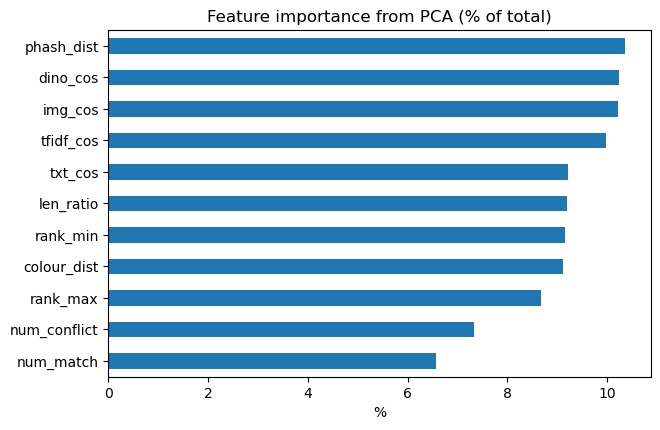

In [21]:
importance = (loadings.abs() * pca.explained_variance_ratio_).sum(axis=1)
importance = (importance / importance.sum() * 100).sort_values(ascending=False)
print(importance.round(1))

importance.sort_values().plot(kind="barh", figsize=(7, 4.5), title="Feature importance from PCA (% of total)")
plt.xlabel("%"); plt.show()

## 6. Should we reduce these features? (logistic regression before and after)

DupeLens's matcher is a logistic regression. We train it to tell *same product* (same or variant) from
*different*, once on all 11 standardised features and once on only the k principal components, and test both
on pairs it never saw (70% train / 30% test). The scaling and the PCA are fitted on the training part only.

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

y = (Y != "different").astype(int)
X_train, X_test, y_train, y_test = train_test_split(A, y, test_size=0.3, random_state=42, stratify=y)

full = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
reduced = make_pipeline(StandardScaler(), PCA(k), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
print("accuracy with all 11 features:", round(100 * full.score(X_test, y_test), 1), "%")
print(f"accuracy with {k} principal components:", round(100 * reduced.score(X_test, y_test), 1), "%")

accuracy with all 11 features: 72.1 %
accuracy with 8 principal components: 61.2 %


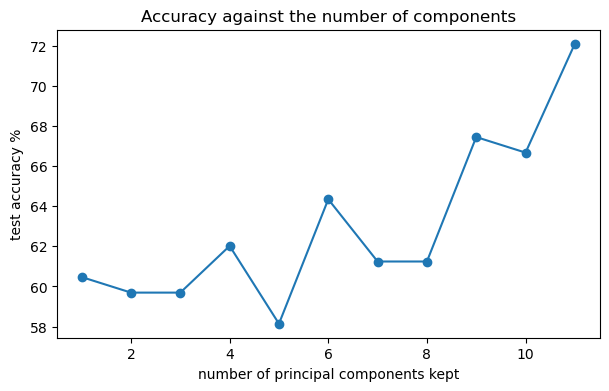

[60.5, 59.7, 59.7, 62.0, 58.1, 64.3, 61.2, 61.2, 67.4, 66.7, 72.1]


In [23]:
acc = []
for n in range(1, len(features) + 1):
    model = make_pipeline(StandardScaler(), PCA(n), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
    acc.append(100 * model.score(X_test, y_test))
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(features) + 1), acc, "o-")
plt.xlabel("number of principal components kept"); plt.ylabel("test accuracy %")
plt.title("Accuracy against the number of components"); plt.show()
print([round(a, 1) for a in acc])

**Result: for these features, PCA should not be used to reduce them.** Keeping 90% of the variance (8
components) lowers the test accuracy, and only all 11 components (which contain exactly the same information as
the 11 features, just rotated) give back the full accuracy.

**Why:** PCA is *unsupervised*: it keeps the directions where the data **varies** most, without looking at the
labels. The last, small-variance directions (PC9 to PC11, only 7.7% of the variance) still carry information that
decides *same vs different*: accuracy climbs from 61.2% with 8 components to 72.1% with all 11. So DupeLens's
logistic regression uses all 11 features as they are.
(Test set: 129 pairs, so a few points of difference is within normal variation; the drop of about 11 points is not.)

PCA **does** help where the data has hundreds of redundant numbers: the neural-network vectors (section 7).

## 7. PCA inside DupeLens: compressing the neural-network vectors

Every listing photo is read by **CLIP** (512 numbers) and every title by **MPNet** (768 numbers). DupeLens
compresses each to **32 numbers** with PCA before comparing listings: fewer numbers, less noise, faster.
Here is the same manual PCA on the 698 Indian listings in our catalogue. (For a symmetric matrix such as a
covariance matrix, `np.linalg.eigh` gives the same result as `eig`, but always as real numbers.)

In [24]:
def manual_pca_variance(X):
    M = np.mean(X.T, axis=1)
    C = X - M
    V = np.cov(C.T)
    eigvalues, eigenvector = np.linalg.eigh(V)
    eigvalues = eigvalues[::-1]                      # largest first
    return np.cumsum(eigvalues) / eigvalues.sum()

clip = np.load("data/clip_photo_vectors.npy")
mpnet = np.load("data/mpnet_title_vectors.npy")
print(clip.shape, mpnet.shape)
cum_clip = manual_pca_variance(clip)
cum_mpnet = manual_pca_variance(mpnet)
print("CLIP photos:  32 components keep", round(100 * cum_clip[31], 1), "% of the variance")
print("MPNet titles: 32 components keep", round(100 * cum_mpnet[31], 1), "% of the variance")

(698, 512) (698, 768)


CLIP photos:  32 components keep 70.8 % of the variance
MPNet titles: 32 components keep 71.2 % of the variance


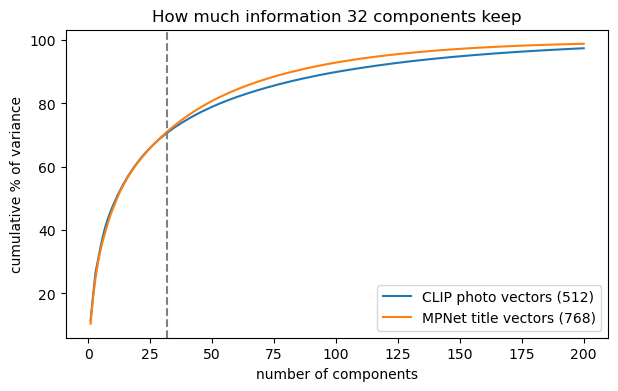

In [25]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, 201), 100 * cum_clip[:200], label="CLIP photo vectors (512)")
plt.plot(range(1, 201), 100 * cum_mpnet[:200], label="MPNet title vectors (768)")
plt.axvline(32, color="grey", linestyle="--")
plt.xlabel("number of components"); plt.ylabel("cumulative % of variance"); plt.legend()
plt.title("How much information 32 components keep"); plt.show()

32 components (out of 512 or 768) keep about **71%** of the variance: the curve rises steeply for the first
components and then flattens, so the remaining hundreds of directions each add very little (mostly fine detail
and noise). The vectors become 16 to 24 times smaller, which makes comparing every pair of listings fast. 32 is the
size used by the trained matcher (validation F1 0.864). In the live system this PCA is fitted once on the 34,250
training listings, not on these 698.

## 8. PCA inside DupeLens: the Genuine Look check

A scam listing often uses the real product's title with **another product's photo**. For each listing of a
product, PCA is fitted on the photos of all the **other** listings (leave-one-out), and we try to rebuild this
photo from the top 3 components. A photo of the real product is rebuilt well; another product's photo is not.

Data: the DINOv2 photo vectors (384 numbers) of the "iPhone 16" listings, plus one photo of Sony headphones that
we slipped in under the iPhone's name.

In [26]:
G = pd.read_csv("data/genuine_demo.csv")
D = G[[f"d{i}" for i in range(384)]].values
D = D / np.linalg.norm(D, axis=1, keepdims=True)
print(D.shape)

def rebuild_error(x, others, k=3):
    M = np.mean(others.T, axis=1)
    C = others - M
    V = np.cov(C.T)
    eigvalues, eigenvector = np.linalg.eigh(V)
    W = eigenvector[:, ::-1][:, :k]                  # top-k components
    z = x - M
    rebuilt = np.dot(np.dot(z, W), W.T)               # project onto the components and back
    return np.linalg.norm(z - rebuilt)

errors = np.array([rebuild_error(D[i], np.delete(D, i, axis=0)) for i in range(len(D))])

(13, 384)


In [27]:
median = np.median(errors)
spread = np.median(np.abs(errors - median)) * 1.4826   # robust standard deviation (median absolute deviation)
z = (errors - median) / spread
genuine = 100 / (1 + np.exp(z - 2.5))                  # 50% exactly at the warning line z = 2.5

result = pd.DataFrame({"store": G["store"], "rebuild error": errors.round(4), "z": z.round(2),
                       "genuine look %": genuine.round(0), "flagged": z > 2.5})
result.sort_values("z", ascending=False)

,store,rebuild error,z,genuine look %,flagged
12,INJECTED (photo of another product),1.0644,21.20,0.0,True
11,Etsy,1.0131,19.86,0.0,True
5,ubuy.co.in,0.9968,19.43,0.0,True
6,S K Mobile-Vadodara,0.4909,6.21,2.0,True
7,iCrescent Apple Authorised Store,0.3231,1.82,66.0,False
3,Unicorn Store,0.2693,0.41,89.0,False
2,iCrescent Apple Authorised Store,0.2533,-0.00,92.0,False
4,vlebazaar.in,0.2534,0.00,92.0,False
0,Reliance Digital,0.2423,-0.29,94.0,False
1,FoneZone.com,0.2333,-0.53,95.0,False


The photo we slipped in has the **largest** rebuild error and is flagged. Three real listings are flagged too, all
from less-known shops (an Etsy item, an import store and a small shop), whose photos are unlike the others. The
big store and the Apple authorised resellers (Reliance Digital, iCrescent, Unicorn) score 66 to 96%. On the website
this is the **Genuine Look %** and the x-axis of the **Scam Radar**; only less-known shops are ever warned about.
(Tested on 13 searches: wrong photos caught 98.4% of the time.)

## 9. Summary

In [28]:
print("Features: 12 measured, 1 constant dropped ->", len(features), "-> principal components kept (90% variance):", k)
print("Most important features (PCA):")
for name, value in importance.head(5).items():
    print(f"  {name:12s} {value:5.1f} %")
print("Least important features:")
for name, value in importance.tail(3).items():
    print(f"  {name:12s} {value:5.1f} %")
print("Accuracy, all 11 features:", round(100 * full.score(X_test, y_test), 1), "% | 8 components:",
      round(100 * reduced.score(X_test, y_test), 1), "% -> the matcher keeps all 11 features")
print("CLIP 512 -> 32 keeps", round(100 * cum_clip[31], 1), "% | MPNet 768 -> 32 keeps", round(100 * cum_mpnet[31], 1), "%")

Features: 12 measured, 1 constant dropped -> 11 -> principal components kept (90% variance): 8
Most important features (PCA):
  phash_dist    10.4 %
  dino_cos      10.2 %
  img_cos       10.2 %
  tfidf_cos     10.0 %
  txt_cos        9.2 %
Least important features:
  rank_max       8.7 %
  num_conflict   7.3 %
  num_match      6.6 %
Accuracy, all 11 features: 72.1 % | 8 components: 61.2 % -> the matcher keeps all 11 features
CLIP 512 -> 32 keeps 70.8 % | MPNet 768 -> 32 keeps 71.2 %
